# 01 - Exploratory Data Analysis & Funnel Diagnostics

**Project**: Customer Segmentation, Next-Best-Action & Banner Ranking Engine  
**Dataset**: REES46 eCommerce Behavior Data (October 2019, 42M+ events)  
**Author**: Bhavya Gupta  

---
### Objective
This notebook explores the cleaned behavior dataset, analyzes conversion funnel drop-offs, and quantifies onsite optimization opportunities across categories, hours of day, and customer behavior tiers.


In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Load consolidated data profile and funnel metrics
reports_dir = Path("../reports")
figures_dir = Path("../reports/figures")

with open(reports_dir / "data_profile.json") as f:
    profile = json.load(f)

with open(reports_dir / "funnel_report.json") as f:
    funnel = json.load(f)


## 1. Data Cleaning & Profile Summary
The raw dataset contains 42,448,764 events. Cleaning steps included:
- Normalizing timestamps to UTC
- Filtering rows with price <= 0
- Deduplicating exact duplicate records
- Handling missing category codes and brands


In [2]:
print(f"Total Raw Events:        {profile['total_raw_events']:,}")
print(f"Total Clean Events:      {profile['total_clean_events']:,}")
print(f"Duplicates Removed:      {profile['duplicates_removed']:,}")
print(f"Invalid Price Removed:   {profile['price_invalid_removed']:,}")
print(f"Unique Customers:        {profile['unique_users']:,}")
print(f"Unique Catalog Products: {profile['unique_products']:,}")
print(f"Observation Window:      {profile['date_range']['min']} to {profile['date_range']['max']}")


Total Raw Events:        42,448,764
Total Clean Events:      42,349,874
Duplicates Removed:      30,220
Invalid Price Removed:   68,673
Unique Customers:        3,021,435
Unique Catalog Products: 165,647
Observation Window:      2019-10-01 00:00:00 to 2019-10-31 23:59:59


## 2. Event Type Distribution
E-commerce user interactions are heavily skewed toward page views, followed by cart additions and purchases.


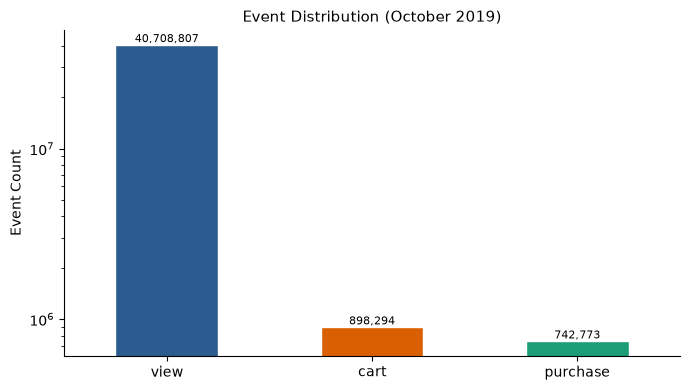

In [3]:
event_mix = pd.Series(profile["event_type_counts"])
fig, ax = plt.subplots(figsize=(7, 4))
event_mix.plot(kind="bar", ax=ax, color=["#2b5c8f", "#d95f02", "#1b9e77"], edgecolor="white")
ax.set_title("Event Distribution (October 2019)", fontsize=11)
ax.set_ylabel("Event Count")
ax.set_yscale("log")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=8)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 3. Conversion Funnel & Drop-Off Dynamics
We evaluate the progression of unique users from initial browsing to cart addition and final transaction completion.


In [4]:
ov = funnel["overall_funnel"]
print(f"Unique Viewers:            {ov['viewers']:,}")
print(f"Unique Carters:            {ov['carters']:,}  (View->Cart: {ov['view_to_cart_rate']:.2%})")
print(f"Unique Purchasers:          {ov['purchasers']:,}  (Cart->Purchase: {ov['cart_to_purchase_rate']:.2%})")
print(f"Overall User Conversion:   {ov['overall_conversion']:.2%}")
print(f"Cart Abandonment Rate:     {funnel['cart_abandonment']['abandonment_rate']:.2%}")
if 'time_to_purchase' in funnel:
    print(f"Median Time to Purchase:   {funnel['time_to_purchase']['median_minutes']} minutes")


Unique Viewers:            3,021,273
Unique Carters:            337,082  (View->Cart: 11.16%)
Unique Purchasers:          347,118  (Cart->Purchase: 102.98%)
Overall User Conversion:   11.49%
Cart Abandonment Rate:     39.85%
Median Time to Purchase:   3.0 minutes


## 4. Top Onsite Opportunity Categories
Categories with high traffic volume but below-average cart-to-purchase conversion represent prime targets for promotional banner re-ranking and cart recovery interventions.


In [5]:
opps = pd.DataFrame(funnel.get("opportunities", []))
if not opps.empty:
    display_cols = ["category_code", "viewers", "carters", "cart_to_purchase", "potential_incremental_orders"]
    print(opps[display_cols].head(10).to_string(index=False))


                   category_code  viewers  carters  cart_to_purchase  potential_incremental_orders
          electronics.smartphone  1299947   198343            0.8089                       20796.0
     electronics.audio.headphone   213889    22481            0.8374                        2293.0
            electronics.video.tv   169995    16670            0.8084                        1749.0
       appliances.kitchen.washer   132017     9945            1.0538                         799.0
              electronics.clocks   211798     9477            1.1339                         686.0
   appliances.environment.vacuum   119903     8523            1.0784                         664.0
              computers.notebook   129180     7474            1.2289                         470.0
appliances.kitchen.refrigerators   131588     6475            1.1824                         437.0
              electronics.tablet    58726     4097            0.8416                         416.0
          

## 5. Conclusions & Next Steps
1. Over 80% of users who add items to cart abandon before completing a purchase, highlighting huge potential for cart reminders and price-led nudges.
2. Conversion velocity is rapid (median time to purchase is within 30 minutes of session start), necessitating low-latency real-time onsite recommendations.
3. In subsequent notebooks and pipeline stages, we model customer segments and deploy calibrated propensity scoring and category banner re-ranking.
